# Do cities with more police have lower crime?

For violent crimes, it seems the opposite.  If I try to do some primitive layering by demographics, the picture doesn't change much.

However, the data itself came from [AI Studio]("https://aistudio.google.com/app/prompts?state=%7B%22ids%22:%5B%2213Aoi0z4QK0uFOJS-0TLO0mZE1LFHCGhF%22%5D,%22action%22:%22open%22,%22userId%22:%22106663353829707201139%22,%22resourceKeys%22:%7B%7D%7D&usp=sharing, https://drive.google.com/file/d/1BrmAVWAzQv8vseCov3dBTzm5AS0u7BTM/view?usp=sharing"), and there was a big list of problems in the dialog.  I doubt they are all fixed, and I didn't check any of the source URLs for hallucination.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

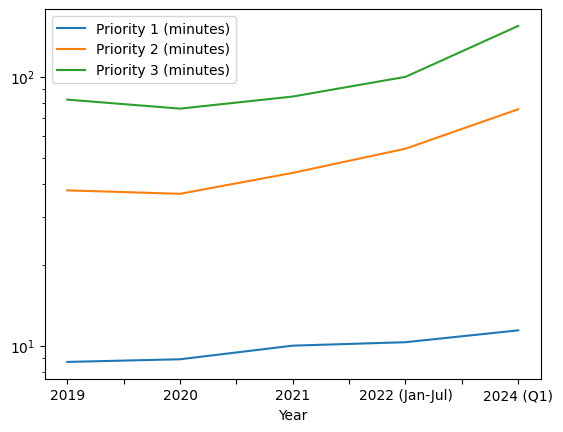

In [3]:
# Seattle response times extracted by https://notebooklm.google.com/notebook/59589c53-913d-42bf-9de1-1152b1b21d96
df = pd.read_csv("./dat/response_times_seattle.csv").set_index('Year').iloc[:,0:3]
df.plot(logy=True, );

In [4]:
df

,Priority 1 (minutes),Priority 2 (minutes),Priority 3 (minutes)
Year,,,
2019,8.7,37.8,82.2
2020,8.9,36.7,76.1
2021,10.0,43.9,84.4
2022 (Jan-Jul),10.3,54.0,99.9
2024 (Q1),11.4,75.7,154.5


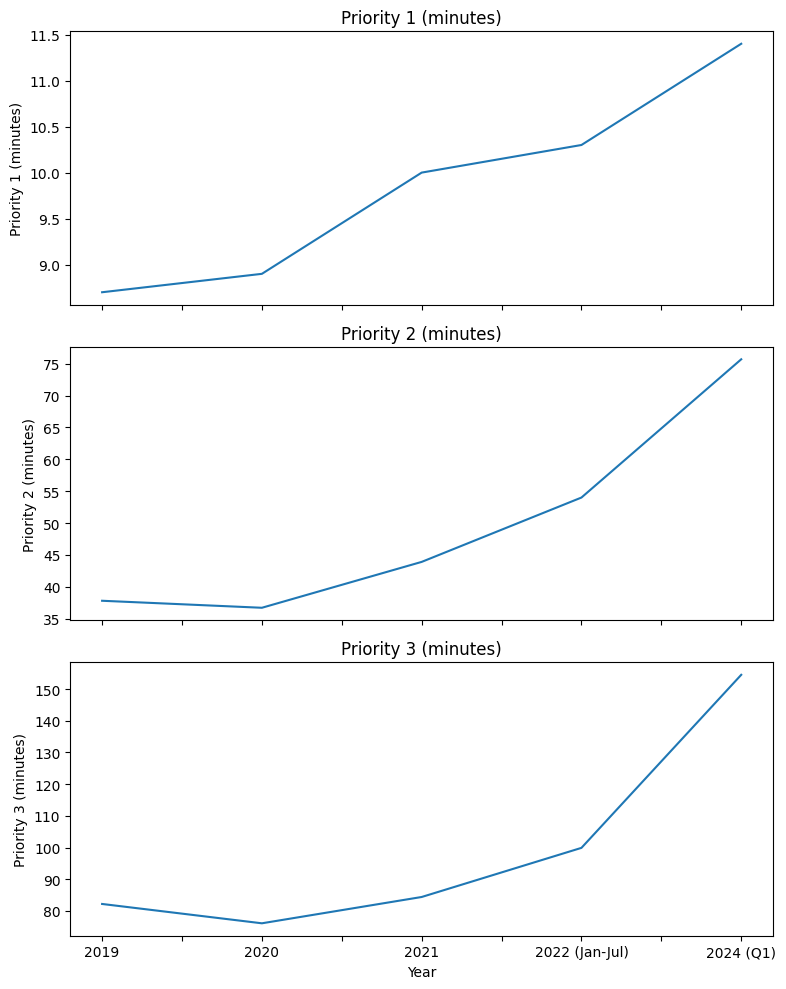

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
for i, col in enumerate(df.columns):
    df[col].plot(ax=axes[i], title=col)
    axes[i].set_ylabel(col)
plt.tight_layout()

ic| col: 'Priority 2 (minutes)'
    y: np.float64(0.0)
    used_y: [np.float64(0.0)]
    vertical_offset: np.float64(4.7381608929054195)
ic| col: 'Priority 3 (minutes)'
    y: np.float64(14.214482678716259)
    used_y: [np.float64(0.0), np.float64(14.214482678716259)]
    vertical_offset: np.float64(4.7381608929054195)
ic| col: 'Priority 1 (minutes)'
    y: np.float64(28.428965357432517)
    used_y: [np.float64(0.0),
             np.float64(14.214482678716259),
             np.float64(28.428965357432517)]
    vertical_offset: np.float64(4.7381608929054195)


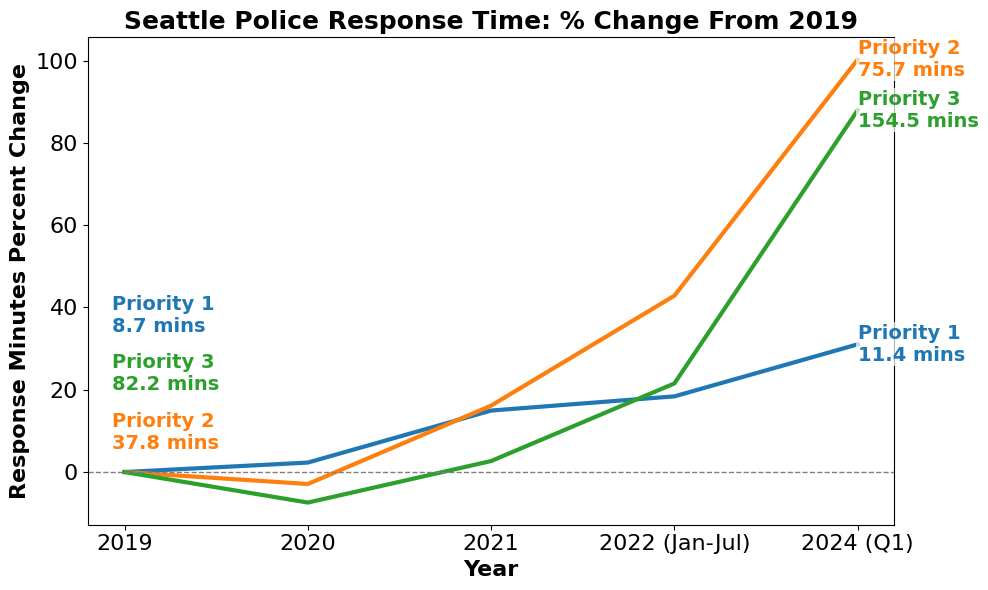

In [10]:
import numpy as np
from icecream import ic

# Calculate percentage change from the first year for each column
df_pct = (df / df.iloc[0] - 1) * 100

fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.tab10.colors  # Use matplotlib's tab10 color palette

# Plot each column and add right-side labels
for i, col in enumerate(df.columns):
    ax.plot(df_pct.index, df_pct[col], label=col, color=colors[i], linewidth=3)
    # Right label (last year)
    ax.text(
        df_pct.index[-1], df_pct[col].iloc[-1],
        f"{col.replace(' (minutes)','')}\n{df.iloc[-1, i]:.1f} mins",
        va='center', ha='left', color=colors[i], fontsize=14, fontweight='bold',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=1)
    )

# --- Sort columns by their last value for correct left label order ---
sorted_cols = [col for _, col in sorted(
    zip([df_pct[col].iloc[-1] for col in df.columns], df.columns),
    reverse=True
)]

# For each sorted column, get the y-value at the leftmost x (first year)
first_x = df_pct.index[0]
label_fontsize = 14
vertical_offset = (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.04  # 4% of axis height

# Compute y-positions: stack above each line's first value, with extra space between
label_ys = []
used_y = []
for col in sorted_cols:
    y = df_pct.loc[first_x, col]
    # Ensure no overlap: if too close to previous, bump up
    if used_y and y - used_y[-1] < vertical_offset:
#        y = used_y[-1] + vertical_offset
        y = used_y[-1] + 3*vertical_offset
    label_ys.append(y)
    used_y.append(y)
    ic(col, y, used_y, vertical_offset)
    

# Offset for left labels to start to the right of the y-axis
x_offset = 0.15
if isinstance(first_x, (int, float)):
    label_x_pos = first_x + x_offset
else:
    xlim = ax.get_xlim()
    label_x_pos = xlim[0] + (xlim[1] - xlim[0]) * 0.03

for i, col in enumerate(sorted_cols):
    color = colors[list(df.columns).index(col)]
    ax.text(
        label_x_pos, label_ys[i] + vertical_offset,  # place just above the line
        f"{col.replace(' (minutes)','')}\n{df.iloc[0, df.columns.get_loc(col)]:.1f} mins",
        va='bottom', ha='left', color=color, fontsize=label_fontsize, fontweight='bold',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=1)
    )

ax.set_ylabel('Response Minutes Percent Change', fontsize=16, fontweight='bold')
ax.set_xlabel('Year', fontsize=16, fontweight='bold')
ax.set_title('Seattle Police Response Time: % Change From 2019', fontsize=18, fontweight='bold')
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.tick_params(axis='both', which='major', labelsize=16)  # Make tick labels bigger
plt.tight_layout()
plt.show()

In [14]:
(75.7-36.8)/36.8

(154.5-82.2)/82.2

0.8795620437956204